# Figure 8: Reward-rate incentives to adjust the bound

How strongly does the reward rate reward choosing the right bound, compared with the noise in the reward rate
a participant experiences in a block? For each condition, every bound policy is compared with the best one,
for an **ideal participant** (no sensory noise, bound variability, guesses or lapses; `pigeon.incentives`).

**Discriminability.** By renewal-reward, a policy's reward rate is ρ = E[c] / E[t] (coins c and steps t per
trial). Over a block of S steps the measured reward rate has variance E[(c − ρt)²] / (S E[t]), so a block of
a policy and a block of the best policy differ by

d′ = (ρ_best − ρ) / √(Var_best + Var),

and the best policy comes out ahead in a fraction Φ(d′) of such comparisons. d′ grows with the square root of
experience, so a policy needs 1/d′² blocks of each to reach d′ = 1. The figure's color scale is this number of
blocks: dark where even many blocks would not tell the policy from the best, white where a fraction of a block
would. Participants played one block per condition.

**Simulations** (`scripts/run_reward_incentives.py`; `data/processed/reward_incentives.pkl`). Every policy of a
condition is applied to the same simulated walks (500,000 trials per SNR in the online task, 200,000 per
change-point time), with the task's trial accounting (`pigeon.simulation.simulate_trials`): the response comes
1 or 2 steps (the cohort's mean fitted NDT distribution) after the walk reaches the bound, a trial costs its RT
including the trial-start step, and a trial that never reaches the bound ends at 50 steps with no coins. The
walls of the screen are ignored, as in Figures 4 and 5.

- **Top row (A–C):** flat bounds in the online task (step SD 0.15; step mean 0.05 at low and 0.15 at high SNR;
  600 steps per block), with the three penalty rules (`BLOCK_DEFAULTS` 1–3). Blocked SNR (cohort 1): each SNR is
  its own block. Mixed SNR (cohort 2): half the trials at each SNR in one block, each SNR with its own bound; the
  row for one SNR shows, at each of its bounds, the d′ of the best policy with that bound (the other SNR's
  bound free). Points: participants' fitted bound plateaus (`stopping_fits_main.pkl`, blocked; `stopping_fits_mx_by_snr.pkl`,
  mixed).
- **Middle row (D, E):** the change-point blocks (step SD 0.05; step mean 0.01 → 0.03 or 0.03 → 0.01 at the
  participant's change point; ±1 coin; 1000 steps per block). D: a flat bound b before the change point and
  b × ratio after it. E: the post-change bound b and a pre-change bound tilted by the slope, b exp(slope (j − cp/2))
  at position j, which keeps the mean pre-change log bound (as in Figure 6). d′ at each ratio or slope is that of
  the best policy with it (b free), computed at each participant's own change point; the strip shows the median
  over participants. Points: participants' fitted step ratios and slopes (`stopping_fits_cp_matched.pkl`, as in
  Figure 6).
- **Bottom row (F):** reserved for the reward-change task (Figure 7).

Edge fits are left out, as in Figures 4 and 5: in the penalty blocks, a plateau at a fit limit or above the screen
edge (`get_plateau_edge_fit`); in the change-point blocks, a plateau at a fit limit (`get_plateau_at_limit`), as in
Figure 6. Counts are printed below. Points beyond the axis are
drawn as triangles at the edge.

In [1]:
import sys
sys.path.insert(0, '..')

import pickle

import matplotlib.pyplot as plt
import matplotlib.ticker as mt
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap

from pigeon.incentives import get_reward_rate_dprime
from pigeon.pathDefaults import DATA_DIR, FIGURES_DIR
from pigeon.plotting import (CM, CONDITION_LABELS, DATA_COLOR, FS_INSET, OPTIMAL_COLOR, add_panel_label,
                             plot_subject_points, use_figure_style)
from pigeon.stopping import get_plateau_at_limit, get_plateau_edge_fit

In [2]:
with open(DATA_DIR / 'reward_incentives.pkl', 'rb') as f:
    sims = pickle.load(f)
BOUNDS, BLOCKS = sims['bounds'], (1, 2, 3)

# Penalty blocks: d' of each (task, block, SNR) bound vs. the best policy of that block.
# Blocked SNR: one SNR per block. Mixed SNR: the half-and-half mixture over (low-SNR bound, high-SNR bound),
# projected on each SNR's bound (the best d' over the other SNR's bound).
dprime, best = {}, {}
for bi, block in enumerate(BLOCKS):
    for snr in ('low', 'high'):
        rho, d = get_reward_rate_dprime(sims['penalty'][('OL', snr)][bi], sims['steps_per_block'])
        dprime[('OL', block, snr)], best[('OL', block, snr)] = d, BOUNDS[np.argmax(rho)]
    lo, hi = sims['penalty'][('MX', 'low')][bi], sims['penalty'][('MX', 'high')][bi]
    rho, d = get_reward_rate_dprime(0.5 * (lo[:, None, :] + hi[None, :, :]), sims['steps_per_block'])
    i_lo, i_hi = np.unravel_index(np.argmax(rho), rho.shape)
    dprime[('MX', block, 'low')], best[('MX', block, 'low')] = d.min(axis=1), BOUNDS[i_lo]
    dprime[('MX', block, 'high')], best[('MX', block, 'high')] = d.min(axis=0), BOUNDS[i_hi]

# Change-point blocks: d' of each ratio / slope (the pre-change bound free) at each change-point time.
CP_AXES = {'step': (0, sims['ratios']), 'slope': (1, sims['slopes'])}
cp_curves = {}
for (cond, cp), m in sims['change_point'].items():
    for name, (k, x) in CP_AXES.items():
        rho, d = get_reward_rate_dprime(m[k], sims['cp_steps_per_block'])
        cp_curves[(name, cond, cp)] = (d.min(axis=0), x[np.unravel_index(np.argmax(rho), rho.shape)[1]])

In [3]:
# Participants' fitted values; edge fits are left out (plateaus as in Figures 4 and 5, change points as in Figure 6).
main = pd.read_pickle(DATA_DIR / 'stopping_fits_main.pkl')
mx = pd.read_pickle(DATA_DIR / 'stopping_fits_mx_by_snr.pkl')
cpf = pd.read_pickle(DATA_DIR / 'stopping_fits_cp_matched.pkl')
main['at_limit'], mx['at_limit'] = get_plateau_edge_fit(main), get_plateau_edge_fit(mx)
cpf = cpf.assign(step=cpf.bound_scale_post / cpf.bound_scale,
                 at_limit=get_plateau_at_limit(cpf) | get_plateau_at_limit(cpf.assign(bound_scale=cpf.bound_scale_post)))


def fitted(task, block, snr):
    # Blocked SNR: raw OL blocks 1-3 are low SNR, 4-6 the same penalties at high SNR.
    if task == 'OL':
        f = main[(main.task == 'OL') & (main.group == f'B{block + (3 if snr == "high" else 0)}')]
    else:
        f = mx[mx.group == f'B{block}_{"lo" if snr == "low" else "hi"}']
    return f.set_index('subject_index')


def blocks_needed(d):
    # Blocks of each policy needed to reach d' = 1 (infinite at the best policy).
    with np.errstate(divide='ignore'):
        return 1 / np.asarray(d, float) ** 2


def summarize(label, x, d, vals, n_limit, log_x=False):
    # Range of policies within one block of the best (d' < 1), and the participants inside it.
    within = x[d < 1]
    xi = np.interp(np.log(vals) if log_x else vals, np.log(x) if log_x else x, d, left=np.inf, right=np.inf)
    print(f'{label}: d\' < 1 for {within.min():.3g}-{within.max():.3g}; participants inside: '
          f'{np.mean(xi < 1):.0%} (n={len(vals)}, median {np.median(vals):.3g}; {n_limit} edge fits)')


ROWS = [('OL', 'low', 'Blocked, low'), ('OL', 'high', 'Blocked, high'),
        ('MX', 'low', 'Mixed, low'), ('MX', 'high', 'Mixed, high')]
print('Penalty blocks (bound plateau; 600-step blocks):')
for block in BLOCKS:
    for task, snr, label in ROWS:
        f = fitted(task, block, snr)
        vals = f.bound_scale[~f.at_limit].dropna().to_numpy()
        summarize(f'  {CONDITION_LABELS[block]}, {label} SNR (best {best[(task, block, snr)]:.2f})', BOUNDS,
                  dprime[(task, block, snr)], vals, int(f.at_limit.sum()))

CP_CONDITIONS = {'LowHigh': ('B3', 3), 'HighLow': ('B4', 4)}   # condition: (fit group, MXSC block)
CP_COLS = {'step': 'step', 'slope': 'slope_pre'}
cp_strip = {}
print('\nChange-point blocks (1000-step blocks; the pre-change bound free):')
for cond, (group, blk) in CP_CONDITIONS.items():
    cps = sims['change_points'].loc[blk]
    f = cpf[cpf.group == group].set_index('subject_index')
    for name, (_, x) in CP_AXES.items():
        D = np.array([cp_curves[(name, cond, cp)][0] for cp in cps])
        bests = np.array([cp_curves[(name, cond, cp)][1] for cp in cps])
        best_med = np.exp(np.median(np.log(bests))) if name == 'step' else np.median(bests)
        cp_strip[(name, cond)] = (np.median(D, axis=0), best_med)
        null = 1.0 if name == 'step' else 0.0
        d_null = np.array([np.interp(np.log(null) if name == 'step' else null, np.log(x) if name == 'step' else x,
                                     cp_curves[(name, cond, cp)][0]) for cp in cps])
        vals = f.loc[~f.at_limit, CP_COLS[name]].dropna().to_numpy()
        summarize(f'  {cond} {name} (best, median over change points {best_med:.3g})', x, np.median(D, axis=0), vals,
                  int(f.at_limit.sum()), log_x=name == 'step')
        print(f'    no adjustment ({null:g}) vs. best: d\' median {np.median(d_null):.2f} [max {d_null.max():.2f}], '
              f'i.e. {np.median(blocks_needed(d_null)):.0f} blocks')

Penalty blocks (bound plateau; 600-step blocks):
  No penalty, Blocked, low SNR (best 0.01): d' < 1 for 0.01-0.08; participants inside: 14% (n=58, median 0.197; 2 edge fits)
  No penalty, Blocked, high SNR (best 0.03): d' < 1 for 0.01-0.11; participants inside: 58% (n=52, median 0.073; 8 edge fits)
  No penalty, Mixed, low SNR (best 0.01): d' < 1 for 0.01-0.1; participants inside: 31% (n=59, median 0.152; 1 edge fits)
  No penalty, Mixed, high SNR (best 0.04): d' < 1 for 0.01-0.19; participants inside: 55% (n=56, median 0.161; 4 edge fits)
  Coin penalty, Blocked, low SNR (best 0.54): d' < 1 for 0.27-0.81; participants inside: 76% (n=55, median 0.422; 5 edge fits)
  Coin penalty, Blocked, high SNR (best 0.19): d' < 1 for 0.1-0.32; participants inside: 57% (n=58, median 0.147; 2 edge fits)
  Coin penalty, Mixed, low SNR (best 0.38): d' < 1 for 0.12-0.81; participants inside: 80% (n=56, median 0.235; 4 edge fits)
  Coin penalty, Mixed, high SNR (best 0.26): d' < 1 for 0.04-0.81; particip

## Figure

Each strip is colored by the number of blocks of each policy needed to tell it from the best (1/d′², log
scale): white where less than 1/16 of a block would, dark red where even 16 blocks would not. Red tick (A–C): the best
policy. D and E have none: their reward-rate surfaces are so flat that the best ratio or slope is set by
simulation noise (it moves between runs), and no value on the axis can be told from it within 16 blocks.
Points: participants (white circles; triangles beyond the axis), black line: their median; dotted line (D, E):
no adjustment at the change point. Saves `Figure08.pdf` (+ `.png`) to `FIGURES_DIR`.

1 extra bytes in post.stringData array


'created' timestamp seems very low; regarding as unix timestamp


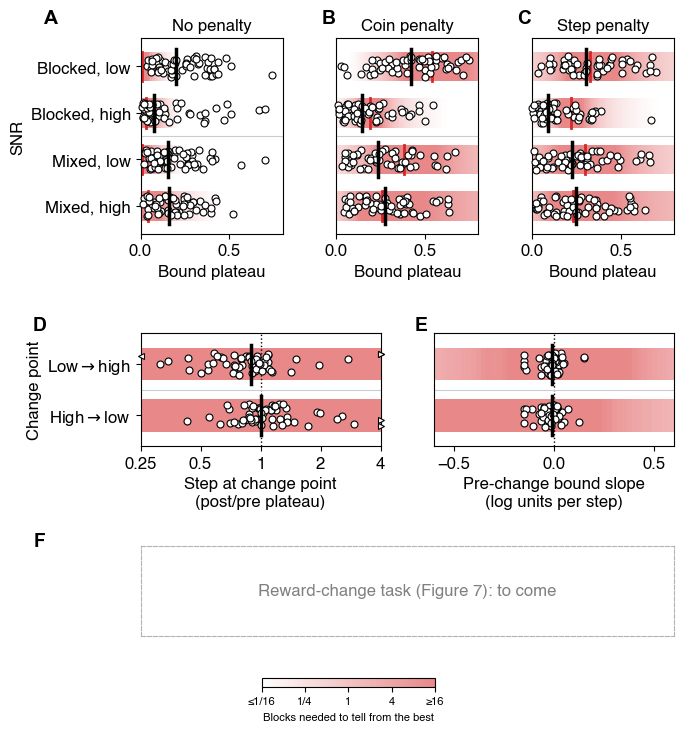

Saved /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Figures/Figure08.pdf (+ .png)


In [4]:
STRIP_H = 0.32
CMAP = LinearSegmentedColormap.from_list('blocks', [(1, 1, 1), OPTIMAL_COLOR])
LOG4_LIM = 2   # color range: 4**-2 = 1/16 to 4**2 = 16 blocks
use_figure_style()
rng = np.random.default_rng(0)   # vertical jitter of the points


def edges(x, log_x):
    # Cell edges halfway between grid points (in log units for a log axis).
    u = np.log(x) if log_x else x
    e = np.r_[u[0] - (u[1] - u[0]) / 2, (u[1:] + u[:-1]) / 2, u[-1] + (u[-1] - u[-2]) / 2]
    return np.exp(e) if log_x else e


def strip_row(ax, y, x, d, best_x, vals, xlim, log_x=False):
    log_blocks = np.log(blocks_needed(d)) / np.log(4)
    im = ax.pcolormesh(edges(x, log_x), [y - STRIP_H, y + STRIP_H], np.clip(log_blocks, -LOG4_LIM, LOG4_LIM)[None, :],
                       cmap=CMAP, vmin=-LOG4_LIM, vmax=LOG4_LIM, alpha=0.55, lw=0, zorder=0, rasterized=True)
    if best_x is None:   # D, E: the best policy is set by simulation noise on these flat surfaces
        pass
    elif xlim[0] <= best_x <= xlim[1]:
        ax.plot([best_x] * 2, [y - STRIP_H, y + STRIP_H], color=OPTIMAL_COLOR, lw=2, zorder=2)
    else:
        left = best_x < xlim[0]
        ax.plot(xlim[0] if left else xlim[1], y, '<' if left else '>', color=OPTIMAL_COLOR, ms=7, clip_on=False, zorder=5)
    plot_subject_points(ax, vals, y + rng.uniform(-0.22, 0.22, len(vals)), xlim=xlim, zorder=3)
    ax.plot([np.exp(np.median(np.log(vals))) if log_x else np.median(vals)] * 2,
            [y - STRIP_H - 0.06, y + STRIP_H + 0.06], color=DATA_COLOR, lw=2.5, zorder=4)
    return im


fig = plt.figure(figsize=(17.6 * CM, 18.5 * CM))
gs = fig.add_gridspec(3, 6, height_ratios=[1.3, 0.75, 0.6], hspace=0.75, wspace=1.2,
                      left=0.2, right=0.97, bottom=0.12, top=0.94)

# A-C: penalty blocks
XLIM = (0, 0.8)
for ci, block in enumerate(BLOCKS):
    ax = fig.add_subplot(gs[0, 2 * ci:2 * ci + 2])
    for ri, (task, snr, label) in enumerate(ROWS):
        f = fitted(task, block, snr)
        im = strip_row(ax, len(ROWS) - 1 - ri, BOUNDS, dprime[(task, block, snr)], best[(task, block, snr)],
                       f.bound_scale[~f.at_limit].dropna().to_numpy(), XLIM)
    ax.axhline(1.5, color='0.8', lw=0.8)   # blocked | mixed
    ax.set_xlim(XLIM)
    ax.set_ylim(-0.6, len(ROWS) - 0.4)
    ax.set_title(CONDITION_LABELS[block])
    ax.set_xlabel('Bound plateau')
    if ci == 0:
        ax.set_yticks(range(len(ROWS))[::-1], [r[2] for r in ROWS])
        ax.set_ylabel('SNR')
    else:
        ax.set_yticks([])
    add_panel_label(ax, 'ABC'[ci], dx=-0.1 if ci else -0.68, dy=1.15)

# D, E: change-point blocks
CP_ROWS = [('LowHigh', r'Low$\rightarrow$high'), ('HighLow', r'High$\rightarrow$low')]
CP_PANELS = [('step', 'Step at change point\n(post/pre plateau)', (0.25, 4), 1.0, True),
             ('slope', 'Pre-change bound slope\n(log units per step)', (-0.6, 0.6), 0.0, False)]
for pi, (name, xlabel, xlim, null, log_x) in enumerate(CP_PANELS):
    ax = fig.add_subplot(gs[1, 3 * pi:3 * pi + 3])
    if log_x:
        ax.set_xscale('log')
    for ri, (cond, label) in enumerate(CP_ROWS):
        f = cpf[cpf.group == CP_CONDITIONS[cond][0]].set_index('subject_index')
        strip_row(ax, len(CP_ROWS) - 1 - ri, CP_AXES[name][1], cp_strip[(name, cond)][0], None,
                  f.loc[~f.at_limit, CP_COLS[name]].dropna().to_numpy(), xlim, log_x)
    ax.axvline(null, color='k', ls=':', lw=1, zorder=1)
    ax.axhline(0.5, color='0.8', lw=0.8)
    if log_x:
        ticks = [0.25, 0.5, 1, 2, 4]
        ax.xaxis.set_major_locator(mt.FixedLocator(ticks))
        ax.xaxis.set_major_formatter(mt.FixedFormatter([f'{t:g}' for t in ticks]))
        ax.xaxis.set_minor_locator(mt.NullLocator())
    ax.set_xlim(xlim)
    ax.set_ylim(-0.6, len(CP_ROWS) - 0.4)
    ax.set_xlabel(xlabel)
    if pi == 0:
        ax.set_yticks(range(len(CP_ROWS))[::-1], [r[1] for r in CP_ROWS])
        ax.set_ylabel('Change point')
    else:
        ax.set_yticks([])
    add_panel_label(ax, 'DE'[pi], dx=-0.45 if pi == 0 else -0.08, dy=1.15)

# F: reserved for the reward-change task (Figure 7)
ax = fig.add_subplot(gs[2, :])
ax.text(0.5, 0.5, 'Reward-change task (Figure 7): to come', ha='center', va='center', color='0.5',
        transform=ax.transAxes)
ax.set_xticks([])
ax.set_yticks([])
for sp in ax.spines.values():
    sp.set_color('0.7')
    sp.set_linestyle('--')
add_panel_label(ax, 'F', dx=-0.2, dy=1.15)

cax = fig.add_axes([0.375, 0.05, 0.25, 0.012])
cb = fig.colorbar(im, cax=cax, orientation='horizontal', ticks=np.arange(-LOG4_LIM, LOG4_LIM + 1))
cb.set_ticklabels(['≤1/16', '1/4', '1', '4', '≥16'])
cb.set_label('Blocks needed to tell from the best', fontsize=FS_INSET)
cax.tick_params(labelsize=FS_INSET)
cb.solids.set_alpha(0.55)

out = FIGURES_DIR / 'Figure08.pdf'
fig.savefig(out, dpi=300, bbox_inches='tight')
fig.savefig(out.with_suffix('.png'), dpi=300, bbox_inches='tight')
plt.show()
print(f'Saved {out} (+ .png)')